# Konfidensintervall
Ett stickprovsmedelvärde är en uppskattning av populationens verkliga medelvärde.  
Eftersom olika stickprov ger olika resultat behöver vi beskriva hur osäker uppskattningen är.  
Ett konfidensintervall kombinerar en uppskattning med en osäkerhetsmarginal.

## Täthet och normalfördelning
Ett vanligt histogram visar hur många observationer som finns i varje intervall.  
Y-axeln visar då antal.  
När density=True används skalas histogrammet i stället som en täthet.  
Den sammanlagda arean av staplarna blir då ungefär 1, vilket gör att histogrammet kan jämföras med en teoretisk täthetskurva.    
Höjden på en täthetskurva är inte sannolikheten för ett exakt värde.   
Sannolikheter motsvaras av arean under kurvan över ett intervall.    
En normalkurva kan vara en rimlig modell när datan är ungefär symmetrisk och klockformad.  
Om histogrammet är tydligt skevt, innehåller flera toppar eller påverkas kraftigt av extremvärden bör vi vara försiktiga med normalantagandet.

### Tre fördelningar att hålla isär
- Datafördelningen visar hur de enskilda observationerna varierar. Histogrammet över personernas längder är ett exempel. Standardavvikelsen beskriver spridningen mellan observationerna.
- Stickprovsfördelningen visar hur en stickprovsstatistik, exempelvis medelvärdet, skulle variera mellan många olika stickprov. Standardfelet beskriver spridningen i denna fördelning.
- Bootstrapfördelningen skapas genom att vi drar många nya stickprov med återläggning från vårt observerade stickprov. Den används för att uppskatta hur stickprovsstatistiken skulle variera mellan olika stickprov.

### Konfidensintervallets grundidé
Ett konfidensintervall kan ofta skrivas som:  
uppskattning ± kritiskt värde × standardfel  
För medelvärdet i normalapproximation används:
stickprovsmedelvärde ± 1,96 × standardfel  
Standardfelet uppskattas med:  
SE = s / √n  
där:  
s är stickprovets standardavvikelse  
n är antalet observationer  
1,96 är det ungefärliga kritiska värdet för ett tvåsidigt 95-procentigt intervall med normalapproximation.

### Så tolkas 95 procents konfidensgrad
Populationens verkliga parameter betraktas som fast, medan intervallet varierar beroende på vilket stickprov vi får.  

Om vi upprepar samma urvals- och beräkningsmetod många gånger kommer ungefär 95 procent av de skapade intervallen att innehålla den verkliga parametern, förutsatt att metodens antaganden är rimliga.  

När ett enskilt intervall redan har beräknats innehåller det antingen parametern eller inte.  
Vi vet vanligtvis inte vilket. Intervallet används ändå som ett rimligt område för parametern utifrån stickprovet och den valda metoden.  
Ett 95-procentigt konfidensintervall betyder INTE:  
- att 95 procent av observationerna ligger inom intervallet  
- att 95 procent av populationen ligger inom intervallet
-  att det är 95 procents sannolikhet att den fasta parametern ligger i just det 

### Vad påverkar intervallbredden?
Ett konfidensintervall blir vanligtvis:  
- smalare när urvalet blir större
- bredare när datan varierar mer
- bredare när vi väljer en högre konfidensgrad
Ett smalt intervall innebär större precision. Det innebär inte automatiskt att uppskattningen är korrekt.  

Ett snedvridet eller icke-representativt urval kan ge ett smalt intervall runt ett missvisande värde.

### Normalapproximation
Normalapproximationen använder en teoretisk formel och är snabb att beräkna. Den fungerar ofta rimligt när:  
- observationerna är tillräckligt oberoende
- urvalet är representativt för populationen
- stickprovsfördelningen för medelvärdet är ungefär normal
- stickprovet inte är alltför litet i förhållande till datans skevhet och extremvärden

Vi använder det kritiska z-värdet 1,96. När populationens standardavvikelse är okänd och uppskattas från stickprovet används i klassisk statistik ofta ett t-intervall, särskilt vid mindre stickprov. Vid större stickprov blir skillnaden mellan z- och t-metoden vanligtvis liten.

### Bootstrap
Bootstrap uppskattar osäkerheten genom att använda det observerade stickprovet:  
- 1. Skapa ett nytt stickprov genom att dra observationer från originalstickprovet med återläggning.
- 2. Beräkna medelvärdet för det nya stickprovet.
- 3. Upprepa processen många gånger.
- 4. Använd exempelvis den 2,5 och 97,5 percentilen av bootstrapmedelvärdena som gränser för ett 95-procentigt intervall.

Återläggning innebär att samma observation kan väljas flera gånger i ett bootstrapstickprov, medan andra observationer kanske inte väljs alls.  
Bootstrap är flexibelt och kräver inte samma analytiska formel som normalmetoden.  
Metoden är däremot inte fri från antaganden.  
Den förutsätter fortfarande att originalstickprovet ger en rimlig bild av populationen.  
Bootstrap kan INTE reparera:
- ett systematiskt snedvridet urval
- felaktiga mätningar
- mycket små stickprov med otillräcklig information
- problem som uppstår för att den valda statistiken är känslig för extremvärden

### Redovisa intervallet tydligt
När du redovisar ett konfidensintervall bör du ange:
- vilken parameter som uppskattas
- punktuppskattningen
- intervallets nedre och övre gräns
- konfidensgraden
- urvalsstorleken
- vilken metod som användes

Exempel på struktur:
Det uppskattade medelvärdet var X enheter, med ett 95-procentigt konfidensintervall från L till H, beräknat med bootstrap utifrån n observationer.  
Diskutera även om urvalet, datakvaliteten eller metodens antaganden begränsar tolkningen.

# Konfidensintervall

In [19]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [20]:
n = 1000
heights  = np.random.normal(loc=172, scale=7, size=n)  # Generate a sample of heights with mean 170 and std dev 7
heights[:5] = [145,198,205,150,190]  # Introduce some outliers

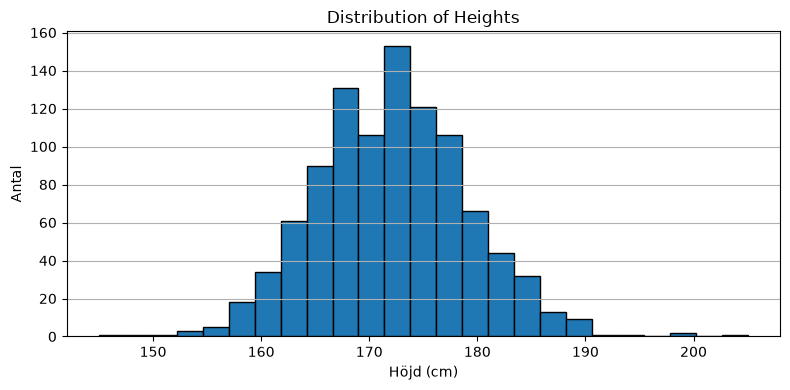

In [21]:
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(heights, bins=25, edgecolor='black')
ax.set_title('Distribution of Heights')
ax.set_xlabel('Höjd (cm)')
ax.set_ylabel('Antal')
ax.grid(True, axis='y')
plt.tight_layout()
plt.show()

In [24]:
mean_x = np.mean(heights)
median_x = np.median(heights)
s = np.std(heights, ddof=1)
print ('medelvärde:', mean_x)
print ('median:', median_x)
print ('standardavvikelse:', s)


medelvärde: 172.1472592866549
median: 172.17710428564422
standardavvikelse: 7.080690527822804


#### Funktionen räknar ut hur hög normalfördelningskurvan är vid ett eller flera angivna x-värden

In [26]:
def normal_pdf(x, m, s):
    # Calculate the probability density function of a normal distribution
    x = np.asarray(x, dtype=float)
    if s <= 0 or not np.isfinite(s):
        raise ValueError('Standard deviation must be positive and finite.')

    norm = 1.0 / (s * np.sqrt(2.0 * np.pi))
    z = (x - m) / s
    y = norm * np.exp(-0.5 * z**2)
    return y

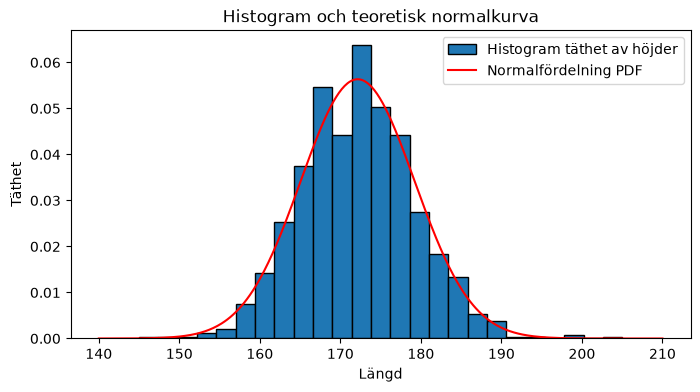

In [30]:
x_support = np.linspace(heights.min() - 5, heights.max() + 5, 400)

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(heights, bins=25, edgecolor='black', density=True, label='Histogram täthet av höjder')

m = np.mean(heights)
s = np.std(heights, ddof=1)
ax.plot(x_support, normal_pdf(x_support, m, s), color='red', label='Normalfördelning PDF')
ax.set_title('Histogram och teoretisk normalkurva')
ax.set_xlabel('Längd')
ax.set_ylabel('Täthet')
plt.legend()

creates a population of 500,000

In [32]:
np.random.seed(123)
population = np.random.normal(loc=50, scale=10, size=500_000)
true_mean = float(np.mean(population))
print(true_mean)

50.010098782870855


calculates mean, std and se

In [51]:
n = 40
x = np.random.choice(population, size=n, replace=True)
mean_x = float(np.mean(x))
s = float(np.std(x, ddof=1))
se = s / np.sqrt(n)
print(f'mean_x: {mean_x:.2f}, standard deviation: {s:.2f}, standard error: {se:.2f}')

mean_x: 49.76, standard deviation: 10.93, standard error: 1.73


function to return high, low of the confidence interval, as well as the sample mean, standard error and number of the sample

In [ ]:
def ci_mean_normal(x, confidence=0.95):
    """p5% confidence interval for the mean of a normal distribution with known standard deviation.
    average +- 1.96 * (std / sqrt(n))"""
    x = np.asarray(x, dtype=float)
    mean_x = float(np.mean(x))
    s = float(np.std(x, ddof=1))
    n = len(x)

    z_critical = 1.96  # For 95% confidence
    half_width = z_critical * (s / np.sqrt(n))
    lo, hi = mean_x - half_width, mean_x + half_width
    return lo, hi, mean_x, s, n

lo, hi , mean_x, s, n = ci_mean_normal(x)
print(lo, hi,'\n', mean_x, '\n', s, n,'\n', true_mean)

46.37773894290625 53.149480703142245 
 49.76360982302425 
 10.925575351440619 40 
 50.010098782870855


diagram med en enda punkt, med felstaplar som visar konfidensintervall

Text(0.5, 1.0, '95% Konfidensintervall för medelvärdet (normalapproximation)')

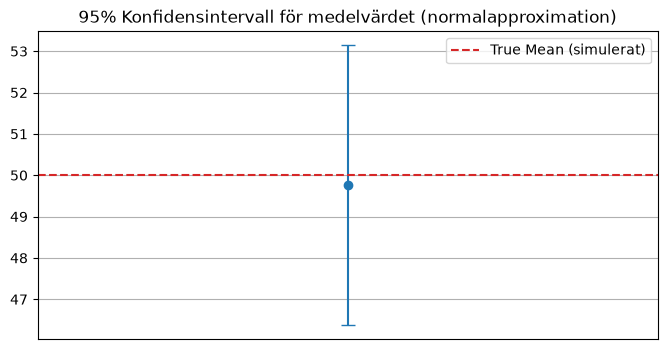

In [67]:
fig, ax = plt.subplots(figsize=(8,4))
ax.errorbar([0], [mean_x], yerr=[[mean_x - lo], [hi - mean_x]], fmt='o', capsize=5)
ax.axhline(y=true_mean, color='tab:red', linestyle='--', label='True Mean (simulerat)')
ax.set_xticks([])
ax.grid(True, axis='y')
ax.legend()
ax.set_title('95% Konfidensintervall för medelvärdet (normalapproximation)')

## bootstrap

In [72]:
def ci_mean_bootstrap(x, B=5000, confidence=0.95):
    """Bootstrap confidence interval for the mean."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    boot_means = np.empty(B)
    for b in range(B):
        boot_sample = np.random.choice(x, size=n, replace=True)
        boot_means[b] = np.mean(boot_sample)

    alpha = (1 - confidence) / 2
    lo, hi = np.percentile(boot_means, [100 * alpha, 100 * (1 - alpha)])
    return float(lo), float(hi), float(np.mean(x))

blo, bhi, bmean= ci_mean_bootstrap(x, B =3000)
(blo, bhi) , bmean, true_mean

((46.161054278865905, 53.11467429650663),
 49.76360982302425,
 50.010098782870855)

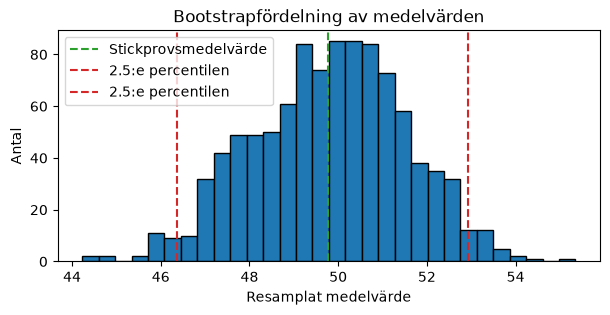

In [83]:
fig, ax = plt.subplots(figsize=(7,3))
bm = np.array([np.mean(np.random.choice(x, size=len(x), replace=True)) for _ in range(1000)])

ax.hist(bm, bins=30, edgecolor='black')
ax.axvline(np.mean(x), color='tab:green', linestyle='--', label='Stickprovsmedelvärde')
ax.axvline(np.percentile(bm, 2.5), color='tab:red', linestyle = '--', label='2.5:e percentilen')
ax.axvline(np.percentile(bm, 97.5), color='tab:red', linestyle = '--', label='2.5:e percentilen')
ax.set_title('Bootstrapfördelning av medelvärden')
ax.set_xlabel('Resamplat medelvärde')
ax.set_ylabel('Antal')
plt.legend()